# Question 3 — Stress Levels by Purpose of Social Media Use

**Research question:** Are there differences in stress levels between users with different primary purposes for using social media?

This notebook builds on the general exploratory data analysis already completed in
`data_exploration/01_data_overview_and_distributions.ipynb` and
`data_exploration/02_feature_relationships_and_dimensionality_reduction.ipynb`.
It does not repeat that EDA — it performs only brief reproducibility checks before moving
directly into the analysis specific to Research Question 3.

- **Explanatory variable:** `Purpose_Of_Use` (Entertainment, Education, Networking, or News)
- **Outcome variable:** `Stress_Level`, ordinal (`Low < Medium < High < Very High`)

This is a statistical exploration notebook, not a predictive-modeling notebook. The goal is
to describe, test, and interpret the association between these two variables — not to build
a classifier. The dataset is observational, so no causal language is used anywhere: results
are described as associations, not effects.

## Hypotheses

- **H0 (null):** The distribution of `Stress_Level` is independent of `Purpose_Of_Use`.
- **H1 (alternative):** The distribution of `Stress_Level` differs for at least one `Purpose_Of_Use` category.

## 0. Setup & Data Loading

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats

sns.set_theme(style='whitegrid', palette='muted', font_scale=1.1)
plt.rcParams['figure.dpi'] = 110

STRESS_ORDER = ['Low', 'Medium', 'High', 'Very High']
STRESS_PALETTE = sns.color_palette('YlOrRd', 4)
PURPOSE_ORDER = ['Entertainment', 'Education', 'Networking', 'News']
PURPOSE_PALETTE = sns.color_palette('Set2', 4)
DATA_PATH = '../dataset/student_social_media_cleaned.csv'
df = pd.read_csv(DATA_PATH)
print('Shape:', df.shape)
df.head()

Shape: (4998, 13)


,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


## 1. Brief Reproducibility Checks

Notebooks 01 and 02 already performed the full data-quality audit (missing values,
duplicates, dtypes, outlier screening) for the whole dataset. Here we only confirm that
the specific columns and category labels needed for Research Question 3 are present and
match expectations.

In [2]:
required_cols = ['Purpose_Of_Use', 'Stress_Level']

assert all(col in df.columns for col in required_cols)
assert set(df['Purpose_Of_Use'].dropna().unique()) == set(PURPOSE_ORDER)
assert set(df['Stress_Level'].dropna().unique()) == set(STRESS_ORDER)

analysis_df = df.dropna(subset=required_cols).copy()

analysis_df['Stress_Level'] = pd.Categorical(
    analysis_df['Stress_Level'],
    categories=STRESS_ORDER,
    ordered=True
)

analysis_df['Purpose_Of_Use'] = pd.Categorical(
    analysis_df['Purpose_Of_Use'],
    categories=PURPOSE_ORDER,
    ordered=False
)

print(f'Observations used: {len(analysis_df):,}')

Observations used: 4,998


## 2. Descriptive Comparison

`Purpose_Of_Use` group sizes are unequal (Entertainment n=2552, Education n=1094,
Networking n=793, News n=561), so comparing **raw counts** of stress levels across groups
would be misleading — a group with more respondents will have larger counts in every stress
category regardless of its actual distribution. The comparison below therefore uses **row
percentages**: for each `Purpose_Of_Use` group, what percentage of its members report each
`Stress_Level`.

### Contingency Table (Row Percentages)

In [3]:
contingency = pd.crosstab(analysis_df['Purpose_Of_Use'],analysis_df['Stress_Level'])
contingency = contingency.reindex(index=PURPOSE_ORDER, columns=STRESS_ORDER)
print('Raw counts:')
print(contingency)

row_pct = contingency.div(contingency.sum(axis=1), axis=0) * 100
print('\nRow percentages (stress distribution within each purpose):')
print(row_pct.round(2))

Raw counts:
Stress_Level    Low  Medium  High  Very High
Purpose_Of_Use                              
Entertainment   307     629   805        810
Education       191     254   264        384
Networking       99     243   209        242
News             46     169   161        185

Row percentages (stress distribution within each purpose):
Stress_Level      Low  Medium   High  Very High
Purpose_Of_Use                                 
Entertainment   12.03   24.66  31.56      31.75
Education       17.47   23.24  24.15      35.13
Networking      12.48   30.64  26.36      30.52
News             8.20   30.12  28.70      32.98


Descriptively, stress-level distributions differ across purposes of social-media use: news users have the lowest proportion of low stress, while education users show both a relatively high proportion of low stress and the highest proportion of very high stress. This suggests that the groups differ in their distribution patterns rather than following a simple order from “less stressed” to “more stressed,” which should be tested statistically in the next step.


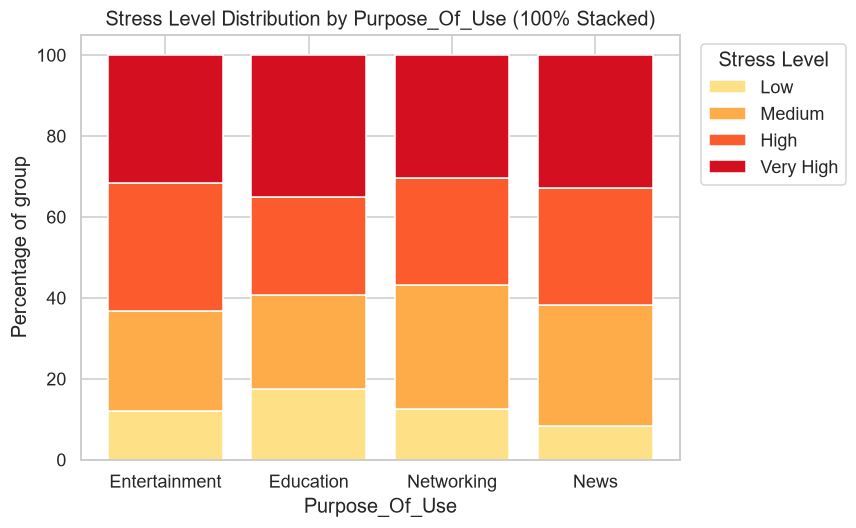

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))

bottom = np.zeros(len(PURPOSE_ORDER))
for i, lvl in enumerate(STRESS_ORDER):
    vals = row_pct[lvl].values
    ax.bar(PURPOSE_ORDER, vals, bottom=bottom, color=STRESS_PALETTE[i], label=lvl, edgecolor='white')
    bottom += vals

ax.set_title('Stress Level Distribution by Purpose_Of_Use (100% Stacked)')
ax.set_ylabel('Percentage of group')
ax.set_xlabel('Purpose_Of_Use')
ax.legend(title='Stress Level', bbox_to_anchor=(1.02, 1), loc='upper left')

plt.tight_layout()
plt.show()

## 3. Statistical Association and Effect Size

### 3A. Chi-Square Test of Independence

**Understanding the p-value.** The null hypothesis is that `Stress_Level` is independent of
`Purpose_Of_Use` (no association). The p-value is the probability of observing a contingency
table at least this skewed by chance if that null hypothesis were true.

- **p ≤ 0.05** → reject H0 → the distributions differ by purpose
- **p > 0.05** → not enough evidence of an association

In [5]:
chi2, p_chi2, dof, expected = stats.chi2_contingency(contingency)

expected_df = pd.DataFrame(expected, index=PURPOSE_ORDER, columns=STRESS_ORDER)
print('Expected frequencies (under H0):')
print(expected_df.round(2))

min_expected = expected.min()
n_below_5 = (expected < 5).sum()
pct_below_5 = n_below_5 / expected.size * 100
print(f'\nMinimum expected frequency: {min_expected:.2f}')
print(f'Cells with expected count < 5: {n_below_5} / {expected.size} ({pct_below_5:.1f}%)')
assumption_ok = n_below_5 == 0
print(f'Chi-square assumption (all expected counts >= 5) satisfied: {assumption_ok}')

print(f'\nChi-square statistic : {chi2:.4f}')
print(f'Degrees of freedom    : {dof}')
print(f'p-value               : {p_chi2:.6e}')
print(f'Significant at α=0.05 : {p_chi2 < 0.05}')

Expected frequencies (under H0):
                  Low  Medium    High  Very High
Entertainment  328.19  660.97  734.47     827.37
Education      140.62  283.20  314.69     354.49
Networking     102.02  205.47  228.32     257.19
News            72.17  145.36  161.52     181.95

Minimum expected frequency: 72.17
Cells with expected count < 5: 0 / 16 (0.0%)
Chi-square assumption (all expected counts >= 5) satisfied: True

Chi-square statistic : 64.6041
Degrees of freedom    : 9
p-value               : 1.722551e-10
Significant at α=0.05 : True


### 3B. Effect Size — Cramér's V

Cramér's V rescales the chi-square statistic to a 0–1 range so association *strength* can be
judged independently of sample size and statistical significance.

In [6]:
n_obs = contingency.values.sum()
r, k = contingency.shape
cramers_v = np.sqrt((chi2 / n_obs) / (min(r - 1, k - 1)))

def interpret_cramers_v(v, deg_freedom_min):
    # Standard thresholds for df_min = min(r-1, c-1) = 1
    if deg_freedom_min == 1:
        thresholds = [0.10, 0.30, 0.50]
    elif deg_freedom_min == 2:
        thresholds = [0.07, 0.21, 0.35]
    else:
        thresholds = [0.06, 0.17, 0.29]
    if v < thresholds[0]:
        return 'negligible'
    elif v < thresholds[1]:
        return 'small'
    elif v < thresholds[2]:
        return 'medium'
    return 'large'

strength = interpret_cramers_v(cramers_v, min(r - 1, k - 1))
print(f"Cramér's V = {cramers_v:.4f} -> practical association strength: {strength}")
print('Note: statistical significance (p-value) and practical strength (Cramér\'s V) are '
      'reported separately because with n=5000, even small associations can be significant.')

Cramér's V = 0.0656 -> practical association strength: small
Note: statistical significance (p-value) and practical strength (Cramér's V) are reported separately because with n=5000, even small associations can be significant.


The chi-square test showed that stress-level distributions differed significantly across primary purposes of social-media use, $\chi^2(9)=64.09,\ p<0.001$. However, Cramér’s $V=0.065$ indicates that the association is very small, meaning that the statistically significant result has limited practical importance.

## 4. Explaining the Result — Pearson Residuals

The chi-square test says the association is significant; it does not say *where* the
significant deviations from independence are. To locate them, we compute, for every
`Purpose_Of_Use` × `Stress_Level` cell:

$$\text{residual} = \frac{\text{observed} - \text{expected}}{\sqrt{\text{expected}}}$$

This quantity is a **Pearson residual**, not a "standardized residual" — that name belongs to
a related but different statistic that additionally divides by
$\sqrt{(1 - \text{row share})(1 - \text{column share})}$ to correct for the fact that the row
and column totals are fixed, which brings it closer to a standard normal distribution. The
formula used here is the simpler Pearson version, so values should be read descriptively — as
a rule-of-thumb flag for cells worth a closer look (|value| > 2 noteworthy, > 3 a strong local
deviation) — rather than as a separately significance-tested z-score.

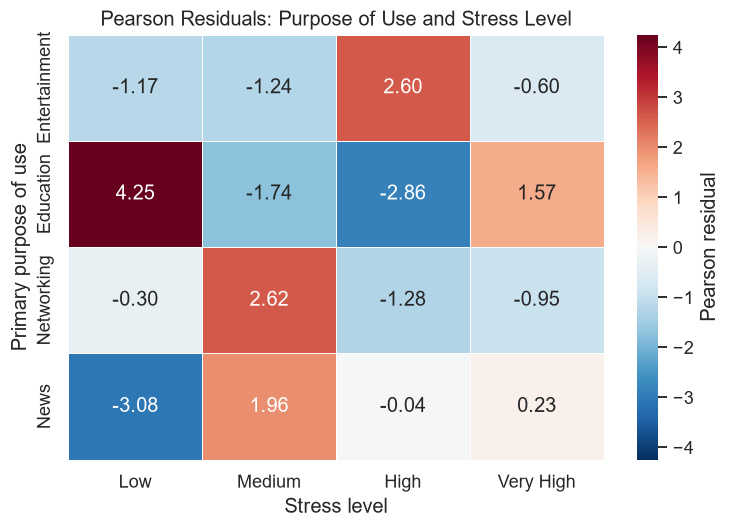

In [7]:
pearson_resid = (contingency - expected_df) / np.sqrt(expected_df)

fig, ax = plt.subplots(figsize=(7, 5))

limit = pearson_resid.abs().to_numpy().max()

sns.heatmap(
    pearson_resid,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-limit,
    vmax=limit,
    linewidths=0.4,
    cbar_kws={'label': 'Pearson residual'},
    ax=ax
)

ax.set_title('Pearson Residuals: Purpose of Use and Stress Level')
ax.set_xlabel('Stress level')
ax.set_ylabel('Primary purpose of use')

plt.tight_layout()
plt.show()

The largest deviations from independence were found for low stress among Education
users, which occurred more often than expected, and low stress among News users,
which occurred less often than expected. Additional deviations included more
high-stress Entertainment users, fewer high-stress Education users, and more
medium-stress Networking users than expected.

These results show that the significant association is driven by specific cells
rather than by a uniform shift from lower to higher stress across the purpose-of-use
groups. This localized pattern is consistent with the very small Cramér’s V.

## 5. Direct Answer to Research Question 3

**Are there differences in stress levels between users with different primary purposes for using social media?**

Yes, but the differences are small. The chi-square test showed that the distribution of
`Stress_Level` differed significantly across `Purpose_Of_Use` groups,
$\chi^2(9)=64.09,\ p<0.001$. All expected cell frequencies were above 5, so the
assumptions of the test were satisfied. However, Cramér’s $V=0.065$ indicates that
the association is very small and has limited practical importance.

The Pearson-residual analysis showed that the association was driven by specific
combinations rather than by a general shift toward higher or lower stress. Education
users showed more low-stress and fewer high-stress observations than expected, News
users showed fewer low-stress observations than expected, Entertainment users showed
more high-stress observations than expected, and Networking users showed more
medium-stress observations than expected.

Therefore, primary purpose of social-media use is weakly associated with the
distribution of stress levels, but it does not provide a simple ranking of which group
is generally more or less stressed.

These findings describe an association in this sample and should not be interpreted
causally. The data are observational, and other factors, such as academic workload,
personality, or personal circumstances, may be related to both purpose of use and
stress level.
Because the data are observational and self-reported, the findings should be interpreted as a weak association rather than a causal relationship.